In [ ]:
import nescafe23 as n23
import nescafe23.beamforming as beamforming
import numpy as np
import matplotlib.pyplot as plt

import acoustic_inversion
import xarray as xr
import pygenray as pr

import cmps

In [2]:
from n23_inversion_ragland.visualization import annotate_beamformer

In [3]:
dss = n23.open_receptions()

100%|██████████| 23/23 [00:16<00:00,  1.37it/s]


In [39]:
Tx_num = 0

thetas = np.linspace(-35,35,200)

upper_Rx = (
    dss[Tx_num]
    .swap_dims({"hydrophone": "nominal_depth"})
    .rename({"nominal_depth": "depth"})[:32]
)

bf, delts = beamforming.ULA_conventional_beamform_nostack(upper_Rx, thetas)

### get a ray run for reference

In [11]:
fctd = n23.compute_filtered_fctd_grid(r_smooth=15e3, z_smooth=300)
fctd = fctd.assign_coords({'range':fctd.range + 35e3})

sound_speed = fctd['c']
bathymetry = xr.DataArray(np.linspace(5000,5000,100), coords={'range':np.linspace(0,160e3, 100)}, dims=['range'])

envi = pr.OceanEnvironment2D(sound_speed, bathymetry)

/home/john.ragland/Code/NESMA/NESCAFE23/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:820: RuntimeWarning: invalid value encountered in sqrt
  result_data = func(*input_data)


In [12]:
source_depth = 2300
receiver_depths = [dss[0].actual_depth[:32].mean().item()]
receiver_range = 155e3
launch_angles = np.linspace(-35,35,5000)

In [14]:
rays = pr.shoot_rays(source_depth, 0, launch_angles, receiver_range, 1000, envi)
eigs = pr.find_eigenrays(rays, receiver_depths, source_depth, 0, receiver_range, 1000, envi, max_iter=100)

Finding eigenrays: 100%|██████████| 50/50 [00:08<00:00,  5.89it/s]


### Plot beamformer output

In [5]:
%matplotlib widget

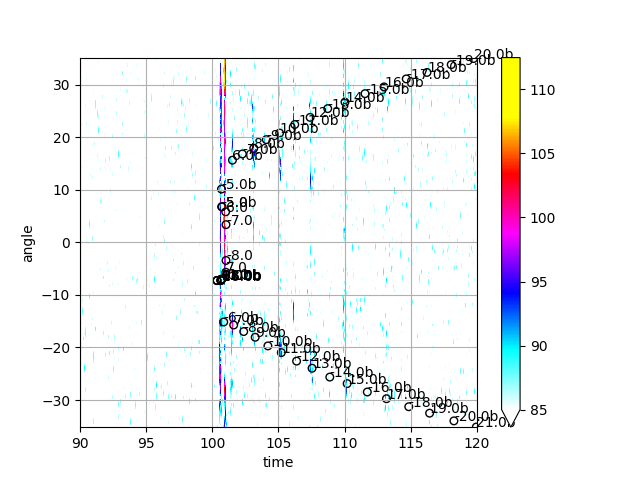

In [40]:
plt.close()
(20*np.log10(np.abs(bf.mean('depth'))))[::10,:].plot(x='time', vmin=85, cmap=cmps.timefront())

plt.scatter(eigs.ts[0][:,-1] - 3.15, eigs.received_angles[0],marker='o', facecolors='none', edgecolor='k', s=30)

for k in range(len(eigs.received_angles[0])):
    plt.text(eigs.ts[0][k,-1] - 3.15, eigs.received_angles[0][k], eigs.ray_id[0][k], color='k')

plt.grid()

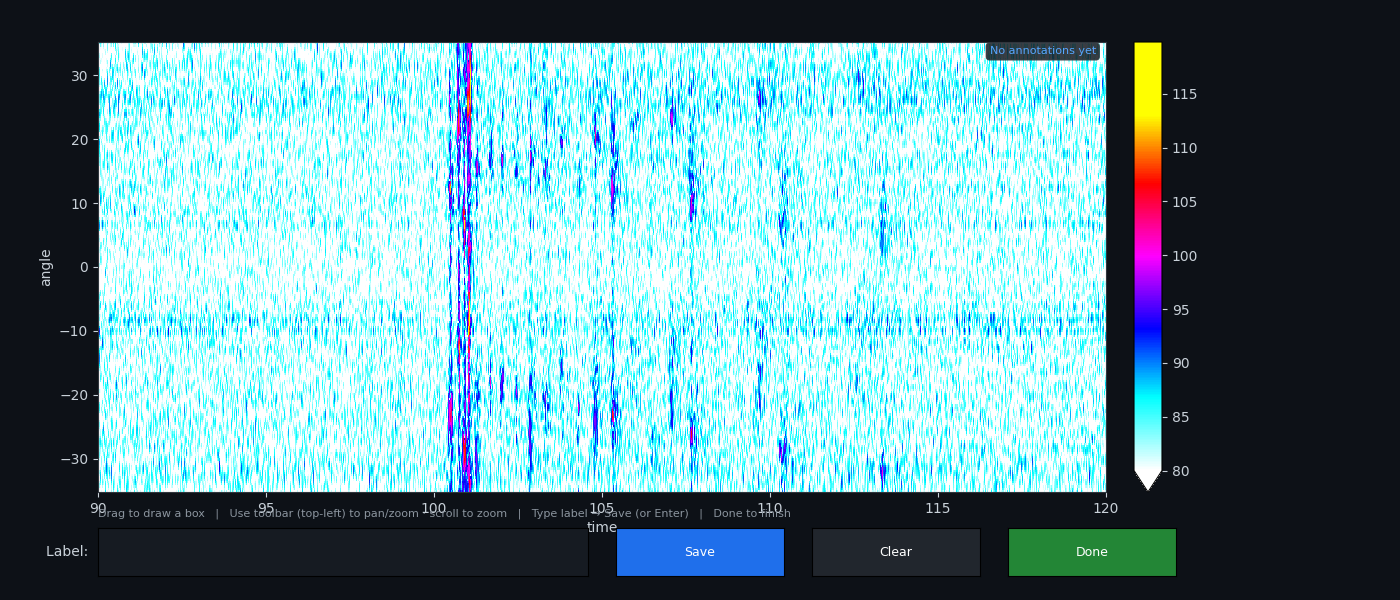

{}

In [7]:
plt.close()
annotate_beamformer(bf.mean('depth')[::10,:], vmin=80)